# Tutorial 1: Quick start on synthetic data

This tutorial runs the whole TxCellNet pipeline on small synthetic sections, on a CPU, in about two minutes:

1. build synthetic sections (DAPI, cell segmentation, transcripts and target protein images);
2. train a stage-1 network;
3. predict a held-out section with `predict_case` and score it at the cell level;
4. train a small stage-2 flow and refine the stage-1 image with `refine`;
5. check that stage 2 keeps every cell mean, and compare the images.

No download is needed. The networks train for a few hundred iterations, enough to show each step; Tutorial 2 trains TxCellNet on real kidney data.

## Setup

Install TxCellNet from the repository root with `pip install -e .` (see Installation). The cell below adds the repository root to the Python path, so the notebook also runs from a fresh clone without installing, and imports the synthetic-section generator of `smoke_test.py` (in the repository root, not part of the package).

In [1]:
import sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

# repository root: holds txcellnet/ and smoke_test.py
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'txcellnet' / '__init__.py').exists())
sys.path.insert(0, str(REPO))

import txcellnet
from txcellnet import GenNet, FlowUNet, geometry, predict_case, refine, metrics, label_counts, default_device
from smoke_test import make_section, batch_inputs, cell_means, GENES, PROTS, CFG

%matplotlib inline
plt.rcParams.update({'figure.dpi': 100, 'image.interpolation': 'nearest'})

T0 = time.time()
torch.manual_seed(0)
rng = np.random.default_rng(0)
device = default_device()
print(f'txcellnet {txcellnet.__version__}, torch {torch.__version__}, device {device}')

txcellnet 1.0.0, torch 2.11.0, device cpu


## Synthetic sections

`make_section` draws Voronoi cells (radius 6.5 px) of three types. Each type expresses its own program of eight genes (80% of its molecules; the rest are drawn from all 24 genes) and one protein channel with its own sub-cellular pattern: `membrane_A` on the cell boundary, `nuclear_B` in the nucleus and `cytoplasm_C` over the whole cell. DAPI is a blurred image of the nuclei.

Measured protein images are grainy, so we multiply each target channel by a smooth random granule pattern with mean one. The expected cell means stay the same, and the targets gain sub-cellular texture that the inputs cannot predict; stage 2 is meant to learn it.

A section is a dict in the format written by the case preparation scripts: `dapi` (z-scored log DAPI), `lab` (cell labels, 0 = background), `genes` (gene names of the panel) and one entry per molecule in `gy`, `gx` (pixel) and `gidx` (index into `genes`). We make 16 training sections of 64 × 64 px and one held-out section of 128 × 160 px.

In [2]:
def add_texture(Y, rng, sd=0.6):
    """multiply each channel by a smooth random granule pattern with mean one"""
    n = np.stack([gaussian_filter(rng.standard_normal(Y.shape[1:]), 1.0) for _ in Y])
    n /= n.std()
    return (Y * np.exp(sd * n - sd ** 2 / 2)).astype(np.float32)


train = []
for _ in range(16):
    case, Y = make_section(rng, 64, 64, 30)
    train.append((case, add_texture(Y, rng)))
test, Y_test = make_section(rng, 128, 160, 150)
Y_test = add_texture(Y_test, rng)

print(f'{len(GENES)} genes, protein channels {PROTS}')
for k, v in test.items():
    print(f'  {k:5s}', f'{v.dtype} array {v.shape}' if isinstance(v, np.ndarray) else f'list of {len(v)} gene names')
print(f'held-out section: {test["lab"].shape[0]} x {test["lab"].shape[1]} px, '
      f'{len(np.unique(test["lab"])) - 1} cells, {len(test["gidx"])} molecules')

24 genes, protein channels ['membrane_A', 'nuclear_B', 'cytoplasm_C']
  dapi  float32 array (128, 160)
  lab   int32 array (128, 160)
  genes list of 24 gene names
  gy    int64 array (5968,)
  gx    int64 array (5968,)
  gidx  int64 array (5968,)
held-out section: 128 x 160 px, 150 cells, 5968 molecules


## Stage 1: train the conditional-mean network

`GenNet` replaces every molecule by a learned embedding of its gene and sums the embeddings at each pixel, together with log(1 + molecule count). This gene field and DAPI enter a U-Net. A cell-neighborhood transformer pools the features into one token per cell, lets nearby cells exchange information and adds each cell's update back to its pixels; a 1 × 1 convolution gives one output channel per protein.

The loss is the mean squared error to the target image, so the network learns the conditional mean. Here we train for 300 iterations on batches of four sections. In the paper, `scripts/train/train_gen.py` trains on batches of sixteen 256-px patches of the kidney sections for 24,000 iterations.

iteration  50  loss 0.1057
iteration 100  loss 0.0575
iteration 150  loss 0.0461
iteration 200  loss 0.0245
iteration 250  loss 0.0114
iteration 300  loss 0.0085
stage 1 trained in 69 s


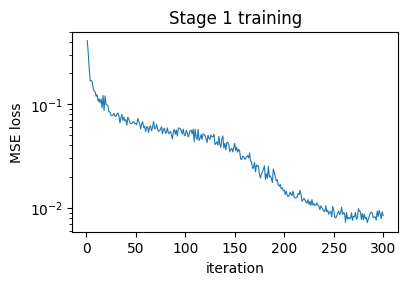

In [3]:
net = GenNet(PROTS, {}, CFG, GENES).to(device)  # CFG: configuration of the paper (learned gene embeddings, summed)
vocab = net.prepare(GENES)                      # genes the model reads; their order defines the gene ids

ITERS1, BS = 300, 4
opt = torch.optim.AdamW(net.parameters(), 1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, 1e-3, total_steps=ITERS1, pct_start=0.05)
loss1, t = [], time.time()
for it in range(1, ITERS1 + 1):
    idx = rng.choice(len(train), BS, replace=False)
    x, tx, lab = batch_inputs([train[i][0] for i in idx], vocab)  # DAPI, molecules (pixel, gene id), cell labels
    y = torch.from_numpy(np.stack([train[i][1] for i in idx])).to(device)
    loss = (net(x, tx, lab) - y).square().mean()
    opt.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
    opt.step()
    sched.step()
    loss1.append(loss.item())
    if it % 50 == 0:
        print(f'iteration {it:3d}  loss {np.mean(loss1[-50:]):.4f}')
net.eval()
print(f'stage 1 trained in {time.time() - t:.0f} s')

fig, ax = plt.subplots(figsize=(4.2, 2.6))
ax.plot(np.arange(1, ITERS1 + 1), loss1, lw=0.8)
ax.set(yscale='log', xlabel='iteration', ylabel='MSE loss', title='Stage 1 training')
plt.show()

## Whole-section prediction

`predict_case` predicts a whole section in windows of up to 1024 px with 64-px context margins, averages four flips and accumulates per-cell sums. It returns the per-cell sums (row 0 = background), the number of molecules read and in total (molecules of genes outside the model's vocabulary are skipped) and, with `image=True`, the image downsampled by `ds`. With `ds=1` the image keeps full resolution, which stage 2 needs.

In [4]:
csum, n_read, n_total, mu = predict_case(net, vocab, test, image=True, ds=1)
n_px = label_counts(test['lab'])
cell_pred = (csum / np.maximum(n_px, 1)[:, None])[1:]  # per-cell means; row k - 1 = cell label k
mu = mu.astype(np.float32)                              # stage-1 image (channels, H, W)
print(f'molecules read: {n_read} of {n_total}')
print(f'per-cell predictions {cell_pred.shape}, stage-1 image {mu.shape}')

molecules read: 5968 of 5968
per-cell predictions (150, 3), stage-1 image (3, 128, 160)


## Cell-level metrics

`txcellnet.metrics` returns the cell-level Pearson and Spearman correlations (Spearman is the primary metric of the paper) and the AUROC for the cells that are positive by an Otsu threshold, with their fraction. Here the truth is the per-cell mean of the target image; with real data it is the log1p measured intensity of each cell.

In [5]:
ok = n_px[1:] > 0                             # labels that own at least one pixel
cell_true = cell_means(Y_test, test['lab'])  # per-cell mean of the target image
pd.DataFrame({p: metrics(cell_pred[ok, j], cell_true[ok, j]) for j, p in enumerate(PROTS)}).T.round(3)

,pearson,spearman,auroc,pos_frac
membrane_A,0.946,0.779,1.000,0.280
nuclear_B,0.866,0.834,0.983,0.333
cytoplasm_C,0.959,0.799,1.000,0.360


Each channel is expressed by one cell type, about a third of the cells. The other cells have a true value of exactly zero; these ties hold the Spearman correlation below the Pearson correlation, while the AUROC shows that the positive cells are found.

## Stage 2: train the residual flow

Stage 2 adds the texture that the conditional mean averages out. A time-conditioned U-Net (`FlowUNet`) learns a rectified flow that carries standard normal noise to the normalized residual r = (Y − μ) / σ, where μ is the stage-1 image and σ the residual SD of each channel. The flow is conditioned only on inputs available for any section: μ, DAPI and three cell-geometry channels from the segmentation (`geometry`: inside-cell mask, cell boundary, distance to the boundary).

As in `scripts/train/train_refine.py`, μ on the training sections is the whole-section stage-1 prediction. Here we train a small `FlowUNet` (widths 32, 64, 128) for 300 iterations; the paper trains the default network (widths 64 to 512) for 30,000 iterations.

In [6]:
mu_train = [predict_case(net, vocab, c, image=True, ds=1)[3].astype(np.float32) for c, _ in train]
R = np.stack([Y - m for (_, Y), m in zip(train, mu_train)])  # residuals Y - mu
rsd = (R.std((0, 2, 3)) + 1e-4).astype(np.float32)          # residual SD per channel
C = np.stack([np.concatenate([m, c['dapi'][None], geometry(c['lab'])])
              for (c, _), m in zip(train, mu_train)]).astype(np.float32)  # condition: mu, DAPI, geometry
print('residual SD per channel:', {p: round(float(v), 3) for p, v in zip(PROTS, rsd)})
print('condition channels:', C.shape[1])

P = len(PROTS)
flow = FlowUNet(P + C.shape[1], P, w=(32, 64, 128), td=128).to(device)  # input: noisy residual + condition
ITERS2 = 300
opt = torch.optim.AdamW(flow.parameters(), 1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, 1e-3, total_steps=ITERS2, pct_start=0.05)
Ct = torch.from_numpy(C).to(device)
Rt = torch.from_numpy(R / rsd[:, None, None]).to(device)  # normalized residual
loss2, t = [], time.time()
for it in range(1, ITERS2 + 1):
    idx = torch.from_numpy(rng.choice(len(train), BS, replace=False)).to(device)
    c, r = Ct[idx], Rt[idx]
    if rng.random() < 0.5: c, r = c.flip(-1), r.flip(-1)
    if rng.random() < 0.5: c, r = c.flip(-2), r.flip(-2)
    s = torch.sigmoid(torch.randn(BS, device=device))  # time on the straight path from noise (0) to residual (1)
    z0 = torch.randn_like(r)
    zs = (1 - s)[:, None, None, None] * z0 + s[:, None, None, None] * r
    loss = (flow(torch.cat([zs, c], 1), s) - (r - z0)).square().mean()  # predict the velocity r - z0
    opt.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(flow.parameters(), 1.0)
    opt.step()
    sched.step()
    loss2.append(loss.item())
    if it % 50 == 0:
        print(f'iteration {it:3d}  loss {np.mean(loss2[-50:]):.4f}')
flow.eval()
print(f'stage 2 trained in {time.time() - t:.0f} s')

residual SD per channel: {'membrane_A': 0.194, 'nuclear_B': 0.141, 'cytoplasm_C': 0.23}
condition channels: 7
iteration  50  loss 1.3691
iteration 100  loss 0.7078
iteration 150  loss 0.5918
iteration 200  loss 0.5356
iteration 250  loss 0.5063
iteration 300  loss 0.5069
stage 2 trained in 28 s


## Refine and check the cell means

`refine` samples a residual by Euler integration of the flow (20 steps from noise scaled by 0.85, the temperature), sets it to zero outside the tissue mask (`inside`; here the whole section) and removes its mean in every cell. Each cell of the refined image therefore keeps its stage-1 mean, and the cell-level metrics above do not change.

In [7]:
out = refine(flow, rsd, mu, test['dapi'], test['lab'], noise=0.85, steps=20)
lab = test['lab']
diff = np.abs(cell_means(out, lab) - cell_means(mu, lab))[ok].max()
print(f'max |cell mean of stage 2 - cell mean of stage 1| = {diff:.1e}')

max |cell mean of stage 2 - cell mean of stage 1| = 1.4e-08


Stage 2 changes the pixels within each cell. The SD of the pixel deviations from their cell mean measures this sub-cellular texture in the truth, the stage-1 image and the refined image:

In [8]:
def within_cell_sd(img, lab):
    """SD of the pixel deviations from their cell mean, over cell pixels, per channel"""
    m = np.vstack([np.zeros(len(img)), cell_means(img, lab)])  # row k = mean of cell label k
    inside = lab > 0
    return [float((img[j] - m[lab, j])[inside].std()) for j in range(len(img))]


pd.DataFrame({name: within_cell_sd(img, lab) for name, img in [('truth', Y_test), ('stage 1', mu), ('stage 2', out)]},
             index=PROTS).round(3)

,truth,stage 1,stage 2
membrane_A,0.315,0.202,0.290
nuclear_B,0.344,0.256,0.319
cytoplasm_C,0.363,0.100,0.291


## Truth, stage 1 and stage 2

A 64 × 96 px window of the held-out section: one row per protein channel, with a shared color scale per row (0 to the 99.5th percentile of the truth). Stage 1 is smooth, as a conditional mean is; stage 2 adds granular texture while every cell keeps its stage-1 mean.

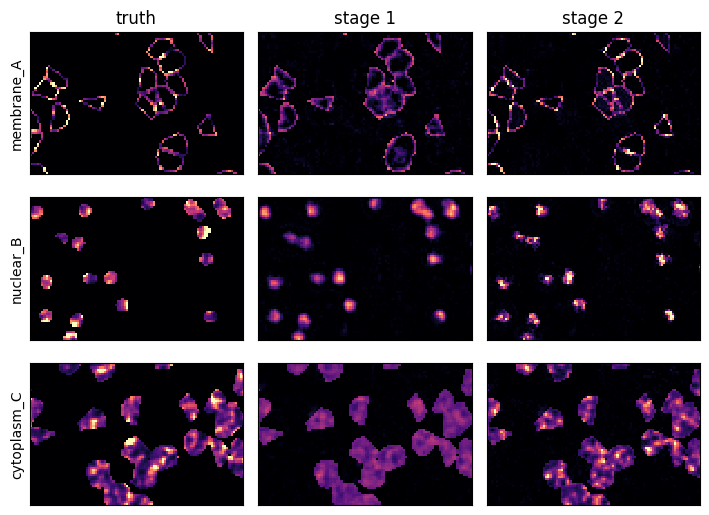

total run time 102 s


In [9]:
win = (slice(32, 96), slice(32, 128))  # rows, columns of the displayed window
fig, axes = plt.subplots(3, 3, figsize=(7.2, 5.4))
for j, p in enumerate(PROTS):
    vmax = np.percentile(Y_test[j], 99.5)
    for k, (name, img) in enumerate([('truth', Y_test), ('stage 1', mu), ('stage 2', out)]):
        ax = axes[j, k]
        ax.imshow(img[j][win], cmap='magma', vmin=0, vmax=vmax)
        ax.set_xticks([])
        ax.set_yticks([])
        if j == 0: ax.set_title(name)
        if k == 0: ax.set_ylabel(p)
fig.tight_layout()
plt.show()
print(f'total run time {time.time() - T0:.0f} s')

## Next steps

Tutorial 2 trains TxCellNet on the two public 10x Genomics kidney Xenium Protein sections, scores the held-out stripes and refines the predictions with stage 2. `python smoke_test.py` runs automated checks of the same pipeline.